In [2]:
import tensorflow as tf
from tensorflow.keras import datasets, layers, models
from tensorflow.keras.optimizers import Adam
import keras
from keras.models import Sequential, Model
from keras.layers import *
from keras.utils import Sequence
from keras.layers import Conv2D, MaxPooling2D, Conv2DTranspose
from qkeras import *

from keras.utils import Sequence
from keras.callbacks import CSVLogger
from keras.callbacks import EarlyStopping
from keras.losses import MeanSquaredError

import os
import random
from datetime import datetime
import time

import matplotlib.pyplot as plt

pi = 3.14159265359

maxval=1e9
minval=1e-9

In [3]:
import importlib
import DAE_DataGenerator
import dataset_utils

importlib.reload(DAE_DataGenerator)
importlib.reload(dataset_utils)
from DAE_DataGenerator import OptimizedDataGenerator
from dataset_utils import add_noise, quantize_manual
#from dataprep import *
# from OptimizedDataGenerator_v2 import OptimizedDataGenerator
from loss import *


In [4]:
dataset_base_dir = "/uscms/home/bweiss/nobackup/smart-pixels/"
tfrecords_base_dir = os.path.join(dataset_base_dir, "tfrecords")

dataset_dir_train = os.path.join(dataset_base_dir, "dataset_3sr_16x16_50x12P5_parquets", 'train/')
dataset_dir_val = os.path.join(dataset_base_dir, "dataset_3sr_16x16_50x12P5_parquets", 'test/')

tfrecords_dir_train = os.path.join(tfrecords_base_dir, "TFR_train",'DAE_digitized_raw')
tfrecords_dir_val   = os.path.join(tfrecords_base_dir, "TFR_val",'DAE_digitized_raw')

print(dataset_dir_val)
batch_size = 5000
val_batch_size = 5000
train_file_size = 80
val_file_size = 20

/uscms/home/bweiss/nobackup/smart-pixels/dataset_3sr_16x16_50x12P5_parquets/test/


In [27]:
start_time = time.time()
validation_generator = OptimizedDataGenerator(
    dataset_base_dir = dataset_dir_val,
    file_type = "parquet",
    data_format = "3D",
    batch_size = val_batch_size,
    # optimize_batch_size = True,
    file_count = val_file_size,
    to_standardize= False,
    log_scale = False,
    select_contained = True,
    noise = [0,80], #[mean, sigma]
    # min_threshold = 400,
    # max_threshold = 1000,
    charge_thresholds= [247.80, 668.41, 1662.85],
    labels_list = ['x-midplane','y-midplane','cotAlpha','cotBeta'],
    input_shape = (2,16,16), # (20,13,21),
    transpose = (0,2,3,1),
    shuffle = False, 
    files_from_end=True,

    tfrecords_dir = tfrecords_dir_val,
    use_time_stamps = [0,19],
    max_workers = 2
)
# validation_generator = [validation_generator[:][0], validation_generator[:][0]]

print("--- Validation generator %s seconds ---" % (time.time() - start_time))

Processing Files...: 100%|██████████| 20/20 [00:04<00:00,  4.12it/s]


Directory /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_val/DAE_digitized_raw does not exist and cannot be removed.


Saving batches as TFRecords: 100%|██████████| 21/21 [00:13<00:00,  1.56it/s]


Metadata saved successfully ast /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_val/DAE_digitized_raw/metadata.json
Loading metadata from /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_val/DAE_digitized_raw/metadata.json


--- Validation generator 18.970906496047974 seconds ---


(5000, 16, 16, 2)
tf.Tensor(
[[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 2. 3. 3. 3. 3. 3. 3. 3. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]], shape=(16, 16), dtype=float32)
<class 'tensorflow.python.framework.ops.EagerTensor'>


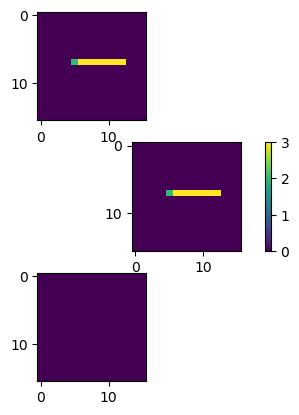

In [70]:
# print(type(validation_generator), len(validation_generator))
# validation_generator = [validation_generator[:][0], validation_generator[:][0]]
# print(type(validation_generator), len(validation_generator))

fig, ax = plt.subplots(3,1)
batch_index = 0
N = 28
ts = 1

X_in = training_generator[batch_index][0][N]
X_out = training_generator[batch_index][1][N]

print(training_generator[N][1].shape)
# X_in = validation_generator[batch_index][0][N]
# X_out = validation_generator[batch_index][1][N]

ax[0].imshow(X_in[:,:,ts]) 
a = ax[1].imshow(X_out[:,:,ts]) 
ax[2].imshow((X_in-X_out)[:,:,ts]) 
print(X_in[:,:,ts])
print(type(X_in))
#indicies: batch_index, in/out, index_in_batch, {nxm pixels}, time slice
# ax[1].imshow(validation_generator[1][11][:,:,1])

fig.colorbar(a)


In [30]:
# training generator
start_time = time.time()
training_generator = OptimizedDataGenerator(
    dataset_base_dir = dataset_dir_train,
    file_type = "parquet",
    data_format = "3D",
    batch_size = batch_size,
    # optimize_batch_size = True,
    file_count = train_file_size,
    to_standardize= False,
    select_contained = True,
    log_scale = False,
    labels_list = ['x-midplane','y-midplane','cotAlpha','cotBeta'],
    input_shape = (2,16,16), # (20,13,21),
    transpose = (0,2,3,1),
    shuffle = False, # True 
    noise = [0,80],
    charge_thresholds= [247.80, 668.41, 1662.85],

    # threshold = 400,
    tfrecords_dir = tfrecords_dir_train,
    use_time_stamps = [0,19],
    max_workers = 2
)

# training_generator = [training_generator[:][0], training_generator[:][0]]

print("--- Training generator %s seconds ---" % (time.time() - start_time))

Processing Files...: 100%|██████████| 80/80 [00:26<00:00,  2.97it/s]


Directory /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_train/DAE_digitized_raw does not exist and cannot be removed.


Saving batches as TFRecords: 100%|██████████| 84/84 [00:52<00:00,  1.60it/s]


Metadata saved successfully ast /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_train/DAE_digitized_raw/metadata.json
Loading metadata from /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_train/DAE_digitized_raw/metadata.json


--- Training generator 80.64403915405273 seconds ---


In [6]:
# Loading pre-generated TFRecords
validation_generator = OptimizedDataGenerator(
    load_from_tfrecords_dir= tfrecords_dir_val,
    shuffle=False,
    # seed=42,
    quantize=False,
)

training_generator = OptimizedDataGenerator(
    load_from_tfrecords_dir = tfrecords_dir_train,
    shuffle=False,
    # seed=42,
    quantize=False,
)

Loading metadata from /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_val/DAE_digitized_raw/metadata.json


Loading metadata from /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_train/DAE_digitized_raw/metadata.json


In [10]:
import models
import loss
importlib.reload(models)
importlib.reload(loss)
from loss import *
from models import CreateAutoEncoder

model=CreateAutoEncoder((16,16,2), n_filters=5, pool_size=2, conv_kernel_size = 3, 
                        decoder_filters = 64, 
                        # input_quant = [1.0,2.0,3.0],
                        input_quant = None
                       )
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    # loss=MeanSquaredError()
    loss=PSNRLoss
)

model.summary()

Model: "model_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_2 (InputLayer)        [(None, 16, 16, 2)]       0         
                                                                 
 q_separable_conv2d_1 (QSepa  (None, 16, 16, 5)        33        
 rableConv2D)                                                    
                                                                 
 q_activation_7 (QActivation  (None, 16, 16, 5)        0         
 )                                                               
                                                                 
 average_pooling2d_2 (Averag  (None, 8, 8, 5)          0         
 ePooling2D)                                                     
                                                                 
 q_activation_8 (QActivation  (None, 8, 8, 5)          0         
 )                                                         

In [11]:
from datetime import datetime
tname = 'DAE_2bit_80eN_NoQOut_PSNR'
fingerprint = '%08x' % random.randrange(16**8)
timestamp = datetime.now().strftime('%Y%m%d-%H%M%S')
os.makedirs("trained_models", exist_ok=True)
base_dir = f'./trained_models/DAE/model-{fingerprint}-{tname}-checkpoints'
os.makedirs(base_dir, exist_ok=True)  
checkpoint_filepath = base_dir + '/weights.{epoch:02d}-t{loss:.4f}-v{val_loss:.4f}.hdf5'
print("fingerprint: ", fingerprint)

fingerprint:  9ff053d7


In [12]:
from tensorflow.keras.callbacks import CSVLogger, EarlyStopping, ModelCheckpoint, Callback

early_stopping_patience = 100

class CustomModelCheckpoint(ModelCheckpoint):
    def on_epoch_end(self, epoch, logs=None):
        super().on_epoch_end(epoch, logs)
        checkpoints = [f for f in os.listdir(base_dir) if f.startswith('weights')]
        if len(checkpoints) > 1:
            checkpoints.sort(key=lambda x: os.path.getmtime(os.path.join(base_dir,x)))
            for checkpoint in checkpoints[:-1]:
                os.remove(os.path.join(base_dir, checkpoint))

es = EarlyStopping(patience=early_stopping_patience, restore_best_weights=True)

mcp = CustomModelCheckpoint(
    filepath=checkpoint_filepath,
    save_weights_only=True,
    monitor='val_loss',
    save_best_only=True,
    save_freq='epoch',
    verbose=1
)

csv_logger = CSVLogger(f'{base_dir}/training_log.csv', append=True)

In [ ]:
history = model.fit(
        x=training_generator,
        validation_data=validation_generator,
        callbacks=[es, mcp, csv_logger],
        epochs=800,
        shuffle=False,
        verbose=1
    )

Epoch 1/800
10/84 [==>...........................] - ETA: 1:32 - loss: -17.7361

In [ ]:
'''Load weights and extract the encoder'''

import models
importlib.reload(models)
from models import CreateAutoEncoder

weights_path = './trained_models/DAE/model-e4177e22-DAE_80eNoise_5filters_convTranspose-checkpoints'
base_dir = weights_path
checkpoint_files = [os.path.join(base_dir, f) for f in os.listdir(base_dir) if f.endswith('.hdf5')]
latest_checkpoint = max(checkpoint_files, key=os.path.getmtime)
#training_cp_path = os.path.join(base_dir, 'training_log.csv')
#training_history = pd.read_csv(training_cp_path)

print(f"Loading model from {latest_checkpoint}")
DAE=CreateAutoEncoder((16,16,2), n_filters=5, pool_size=2, conv_kernel_size = 3)
DAE.load_weights(latest_checkpoint)
model_summary = [[layer.name, layer.output.shape] for layer in DAE.layers]

# for layer in DAE.layers:
#     print(layer.name)

layer_name = DAE.layers[8].name 
# print(layer_name)
encoder = Model(inputs=DAE.input, outputs=DAE.get_layer(layer_name).output)
encoder.trainable = False
encoder.summary()

print(encoder.output.shape)



In [ ]:
'''attach a dense regression network to the latent space'''
from models import var_network

x_in = encoder.input
lat_shape = encoder.output.shape
dense = var_network(encoder.output, hidden=16, output=14)
model = Model(inputs=x_in, outputs=dense)

model.summary()